In [1]:
%load_ext autoreload
%autoreload 2

In [2]:
import numpy as np
import lib.io
import lib.computation
import lib.shiroma

In [3]:
in_path = lib.io.normpath("s3://bopen-sar/ARD-ROSE-L/SAOCOM/Naples/ASC/S4")
slc_path = f"{in_path}/slcs.zarr/coreg"
acquisition_date = "2023-12-12T04:51:48.236453"
wdir_path = f"{in_path}/SHIROMA"
selection_path = f"{wdir_path}/selection"
global_values_path = f"{wdir_path}/global_values"
rtc_ap_path = f"{wdir_path}/rtc_ap"

In [4]:
slc = lib.io.read(slc_path).cstack.sel(acquisition_date=acquisition_date)
selection = lib.io.read(selection_path)
A = lib.io.read(rtc_ap_path, mask_and_scale=False).v

In [5]:
data_name = "flattened_intensity"
c = lib.shiroma.flatten_radar_image(slc, A, wdir_path, data_name=data_name, read=True)

In [6]:
c_path = f"{wdir_path}/{data_name}"
g = lib.shiroma.map_geo_ap(c_path, selection, wdir_path, data_name="geo_ap", read=True)

2025-02-13 09:55:51 [warning  ] No global client found a new one will be created
2025-02-13 09:55:51 [debug    ] <Cluster info: type=LOCAL, n_jobs=64, job_memory=1962303158>
2025-02-13 09:55:53 [debug    ] Selected scatter strategy: once-and-for-all
2025-02-13 09:55:53 [debug    ] Number of blocks to be processed: 1312


2025-02-13 09:56:45,928 - distributed.scheduler - ERROR - Removing worker 'tcp://127.0.0.1:44459' caused the cluster to lose scattered data, which can't be recovered: {'Dataset-467db9628d6353050fd2eb52f9c2f2c8', 'str-4f9afa7a1a67c77f73d5c4fe10cc162b', 'int-57f90bedeea3ef51aa1e912ae32f0ae1', 'str-16d4b0565a8ab5d32c19cf0b7c33f21c', 'str-808b5ce26b854a04f5da3f110bc9d9a2', 'int-b134b498f0d07d794e5900e879e42c89'} (stimulus_id='handle-worker-cleanup-1739440605.9285839')


In [7]:
g = lib.io.read(f"{wdir_path}/geo_ap", mask_and_scale=False).v
g_2 = np.abs(g) ** 2

In [8]:
g_2.max().values, g_2.min().values

(array(179619.95, dtype=float32), array(0., dtype=float32))

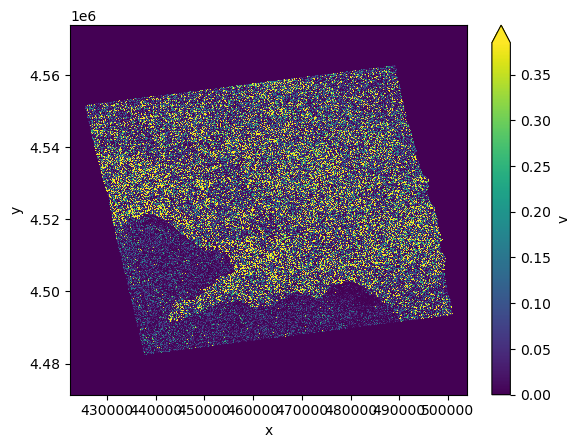

In [9]:
g_2.plot(vmin=0, vmax=3.0 * g_2.mean().values)